## DBSCAN Example

In [6]:
import numpy as np
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt

from sklearn.preprocessing import MinMaxScaler
from sklearn.cluster import DBSCAN

Let's begin by loading the data. We don't want to include customer score when we do clustering so, we'll select the features we need.

In [8]:
df = pd.read_csv('Mall_Customers.csv')
X = df[['Age', 'AnnualIncome', 'SpendingScore']]
X

,Age,AnnualIncome,SpendingScore
0,19,15,39
1,21,15,81
2,20,16,6
3,23,16,77
4,31,17,40
...,...,...,...
195,35,120,79
196,45,126,28
197,32,126,74
198,32,137,18


Distance-based methods should be scaled first.

In [10]:
scaler = MinMaxScaler(feature_range=(0,10))
model = scaler.fit(X)
scaled_X = model.transform(X) # gives a ndarry
# put this back into a dataframe
X = pd.DataFrame(scaled_X, columns=X.columns)

Now we can create our DBSCAN model.
We'll specify max distance between samples for them to be consider in the same neighborhood (esp). This is the most important parameter to consider.
We'll also specify the min number of samples needed for a point to be considered a core point. 


In [54]:
DBSCANmodel = DBSCAN(eps=1, min_samples=7).fit(X)

Let's now add cluster labels to each observation in the ORIGINAL dataset.

In [56]:
df.loc[:,'Cluster'] = DBSCANmodel.labels_ 
df['Cluster'] = df['Cluster'].astype(int)
df

C:\Users\alm36\AppData\Local\Temp\ipykernel_16224\696231858.py:1: FutureWarning: Setting an item of incompatible dtype is deprecated and will raise in a future error of pandas. Value '[-1 -1 -1 -1 -1 -1 -1 -1 -1 -1 -1 -1 -1 -1 -1 -1 -1 -1 -1 -1 -1 -1 -1 -1
 -1 -1 -1 -1 -1 -1 -1 -1 -1 -1 -1 -1 -1 -1 -1 -1 -1 -1 -1 -1 -1 -1 -1 -1
 -1 -1  0 -1 -1 -1  0  0  0 -1  1  0 -1  1 -1 -1 -1  1  0 -1  1 -1 -1  0
 -1 -1 -1  1  0 -1  1  0 -1 -1 -1  0  1  0 -1  1 -1  0  2  1  0 -1 -1  1
  0  1  0  1  1  0  2  1  0  1  2  0  2  2  2  1 -1  1  1  1  2 -1  0 -1
  1 -1 -1 -1 -1  3 -1 -1 -1  3 -1  3 -1  3 -1  4 -1  3 -1  3 -1  4 -1  4
 -1  4 -1  3 -1  4 -1  4 -1  3 -1  4 -1  3 -1  3 -1  3 -1  4 -1  3 -1  4
 -1 -1 -1  3 -1  4 -1  4 -1 -1 -1 -1 -1 -1 -1 -1 -1 -1 -1 -1 -1 -1 -1 -1
 -1 -1 -1 -1 -1 -1 -1 -1]' has dtype incompatible with int32, please explicitly cast to a compatible dtype first.
  df.loc[:,'Cluster'] = DBSCANmodel.labels_


,CustomerID,Gender,Age,AnnualIncome,SpendingScore,Cluster
0,1,Male,19,15,39,-1
1,2,Male,21,15,81,-1
2,3,Female,20,16,6,-1
3,4,Female,23,16,77,-1
4,5,Female,31,17,40,-1
...,...,...,...,...,...,...
195,196,Female,35,120,79,-1
196,197,Female,45,126,28,-1
197,198,Male,32,126,74,-1
198,199,Male,32,137,18,-1


Let's just see how many observations belong to each cluster.

In [58]:
df.value_counts("Cluster").to_frame()

,count
Cluster,
-1,130
1,20
0,19
3,13
4,11
2,7


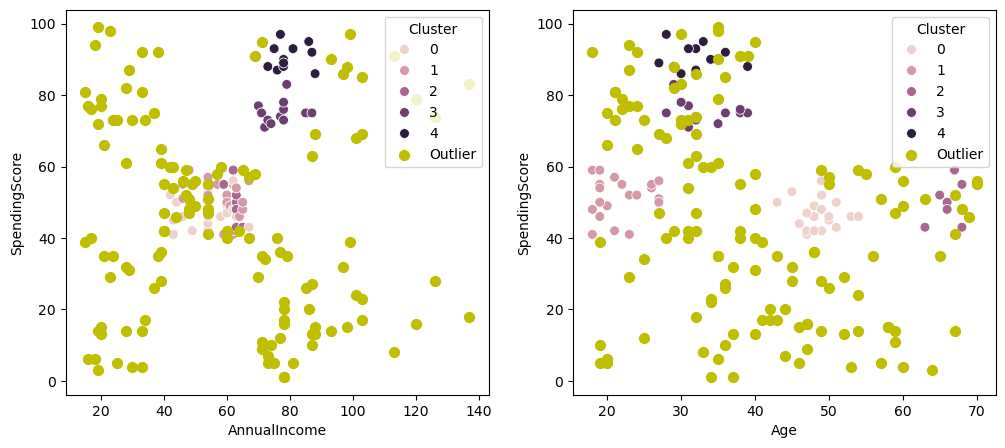

In [59]:
# get outliers
outliers = df[df['Cluster']==-1]

# get non-outliers
non_outliers = df[df['Cluster']!=-1]

fig, (axes) = plt.subplots(1,2, figsize=(12,5))

# plot the clusters
sns.scatterplot(x='AnnualIncome', y='SpendingScore', data=non_outliers, hue='Cluster', ax=axes[0], s=50)
sns.scatterplot(x='Age', y='SpendingScore', data=non_outliers, hue='Cluster', ax=axes[1], s=50)

# add outliers to each plot
axes[0].scatter(outliers['AnnualIncome'], outliers['SpendingScore'], s=50, label='Outlier', c="y")
axes[1].scatter(outliers['Age'], outliers['SpendingScore'], s=50, label='Outlier', c="y")

# add legend
axes[0].legend()
axes[1].legend()

# see https://seaborn.pydata.org/generated/seaborn.move_legend.html
sns.move_legend(axes[0], "upper right", title="Cluster")
sns.move_legend(axes[1], "upper right", title="Cluster")

plt.show()